# Visibility maps viewer
Displays the visibility maps of `dataset/visibility/` (made by `make_visibility_maps.py`): for each map, the city with
the ground station, the SNR of every cell and the visibility (green = visible, red = not visible, grey = inside a
building taller than the drone). Choose the split in the first cell, then use the sliders.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import ipywidgets as widgets

SPLIT = "val"                                   # "train", "val", "test" or "ood"
VIS_DIR = Path("../dataset/visibility")

d = np.load(VIS_DIR / f"visibility_{SPLIT}.npz")
vis, valid = d["visibility"], d["valid"]
snr = d["snr_db"] if "snr_db" in d.files else None
heights, scene_names, scene_idx = d["heights"], d["scene_names"], d["scene_idx"]
station, altitude = d["station_pos"], d["altitude"]
budget = json.loads(str(d["link_budget"]))
print(f"{SPLIT}: {len(vis)} maps from {len(scene_names)} scenes; {100 * vis[valid].mean():.1f} % of the valid cells visible")
print("link budget:", budget)

val: 1620 maps from 135 scenes; 91.5 % of the valid cells visible
link budget: {'tx_power_dbm': 20.0, 'tx_gain_dbi': 0.0, 'rx_gain_dbi': 0.0, 'bandwidth_hz': 20000000.0, 'noise_figure_db': 7.0, 'noise_psd_dbm_hz': -174.0, 'noise_power_dbm': -93.99, 'snr_threshold_db': 0.0, 'min_path_gain_db': -113.99}


In [2]:
EXTENT = (-64, 64, -64, 64)                     # cell [i, j] has its centre at x = j - 63.5 m, y = i - 63.5 m
VIS_CMAP = ListedColormap(["#d62728", "#2ca02c", "0.6"])       # red = not visible, green = visible, grey = building


def visibility_image(k):
    return np.where(valid[k], vis[k], 2)


def show_map(k):
    """City, SNR and visibility of map k."""
    s = scene_idx[k]
    n = 3 if snr is not None else 2
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5.2))
    im = axes[0].imshow(heights[s], origin="lower", cmap="magma", extent=EXTENT)
    axes[0].set_title(f"{scene_names[s]}: building height (m)")
    plt.colorbar(im, ax=axes[0], fraction=0.046)
    if snr is not None:
        cm = plt.get_cmap("viridis").copy()
        cm.set_bad("0.6")
        im = axes[1].imshow(np.ma.masked_where(~valid[k], snr[k].astype(float)), origin="lower", cmap=cm,
                            extent=EXTENT)
        axes[1].set_title(f"SNR (dB), threshold {budget['snr_threshold_db']:g} dB")
        plt.colorbar(im, ax=axes[1], fraction=0.046)
    axes[-1].imshow(visibility_image(k), origin="lower", cmap=VIS_CMAP, vmin=-0.5, vmax=2.5, extent=EXTENT,
                    interpolation="nearest")
    axes[-1].set_title(f"visibility: {100 * vis[k][valid[k]].mean():.0f} % of the valid cells visible")
    for ax in axes:
        ax.plot(station[k, 0], station[k, 1], "c*", ms=15, mec="k")
        ax.set_xticks([]), ax.set_yticks([])
    fig.suptitle(f"{SPLIT} map {k}: drone altitude {altitude[k]:.0f} m, station at "
                 f"({station[k, 0]:.1f}, {station[k, 1]:.1f}, {station[k, 2]:.1f}) m")
    plt.tight_layout()
    plt.show()


widgets.interact(show_map, k=widgets.IntSlider(value=0, min=0, max=len(vis) - 1, description="map"));

interactive(children=(IntSlider(value=0, description='map', max=1619), Output()), _dom_classes=('widget-intera…

## All maps of one scene
Every scene has 3 ground stations (rows) and 4 drone altitudes (columns).

In [3]:
def show_scene(s):
    """The visibility maps of every station and altitude of scene s."""
    ks = np.where(scene_idx == s)[0]
    stations = np.unique(station[ks], axis=0)
    alts = np.unique(altitude[ks])
    fig, axes = plt.subplots(len(stations), len(alts), figsize=(4 * len(alts), 4 * len(stations)), squeeze=False)
    for k in ks:
        r = int(np.where((stations == station[k]).all(axis=1))[0][0])
        c = int(np.where(alts == altitude[k])[0][0])
        ax = axes[r, c]
        ax.imshow(visibility_image(k), origin="lower", cmap=VIS_CMAP, vmin=-0.5, vmax=2.5, extent=EXTENT,
                  interpolation="nearest")
        ax.plot(station[k, 0], station[k, 1], "c*", ms=12, mec="k")
        ax.set_title(f"map {k}: {altitude[k]:.0f} m, {100 * vis[k][valid[k]].mean():.0f} % visible", fontsize=10)
        ax.set_xticks([]), ax.set_yticks([])
    fig.suptitle(f"{SPLIT} scene {s}: {scene_names[s]} (green = visible, red = not visible, grey = building)")
    plt.tight_layout()
    plt.show()


widgets.interact(show_scene, s=widgets.IntSlider(value=0, min=0, max=len(scene_names) - 1, description="scene"));

interactive(children=(IntSlider(value=0, description='scene', max=134), Output()), _dom_classes=('widget-inter…

## One example per city family in each split
For every split, the first scene of each family: its building height map, then the visibility maps of its first ground station at the 4 drone altitudes.

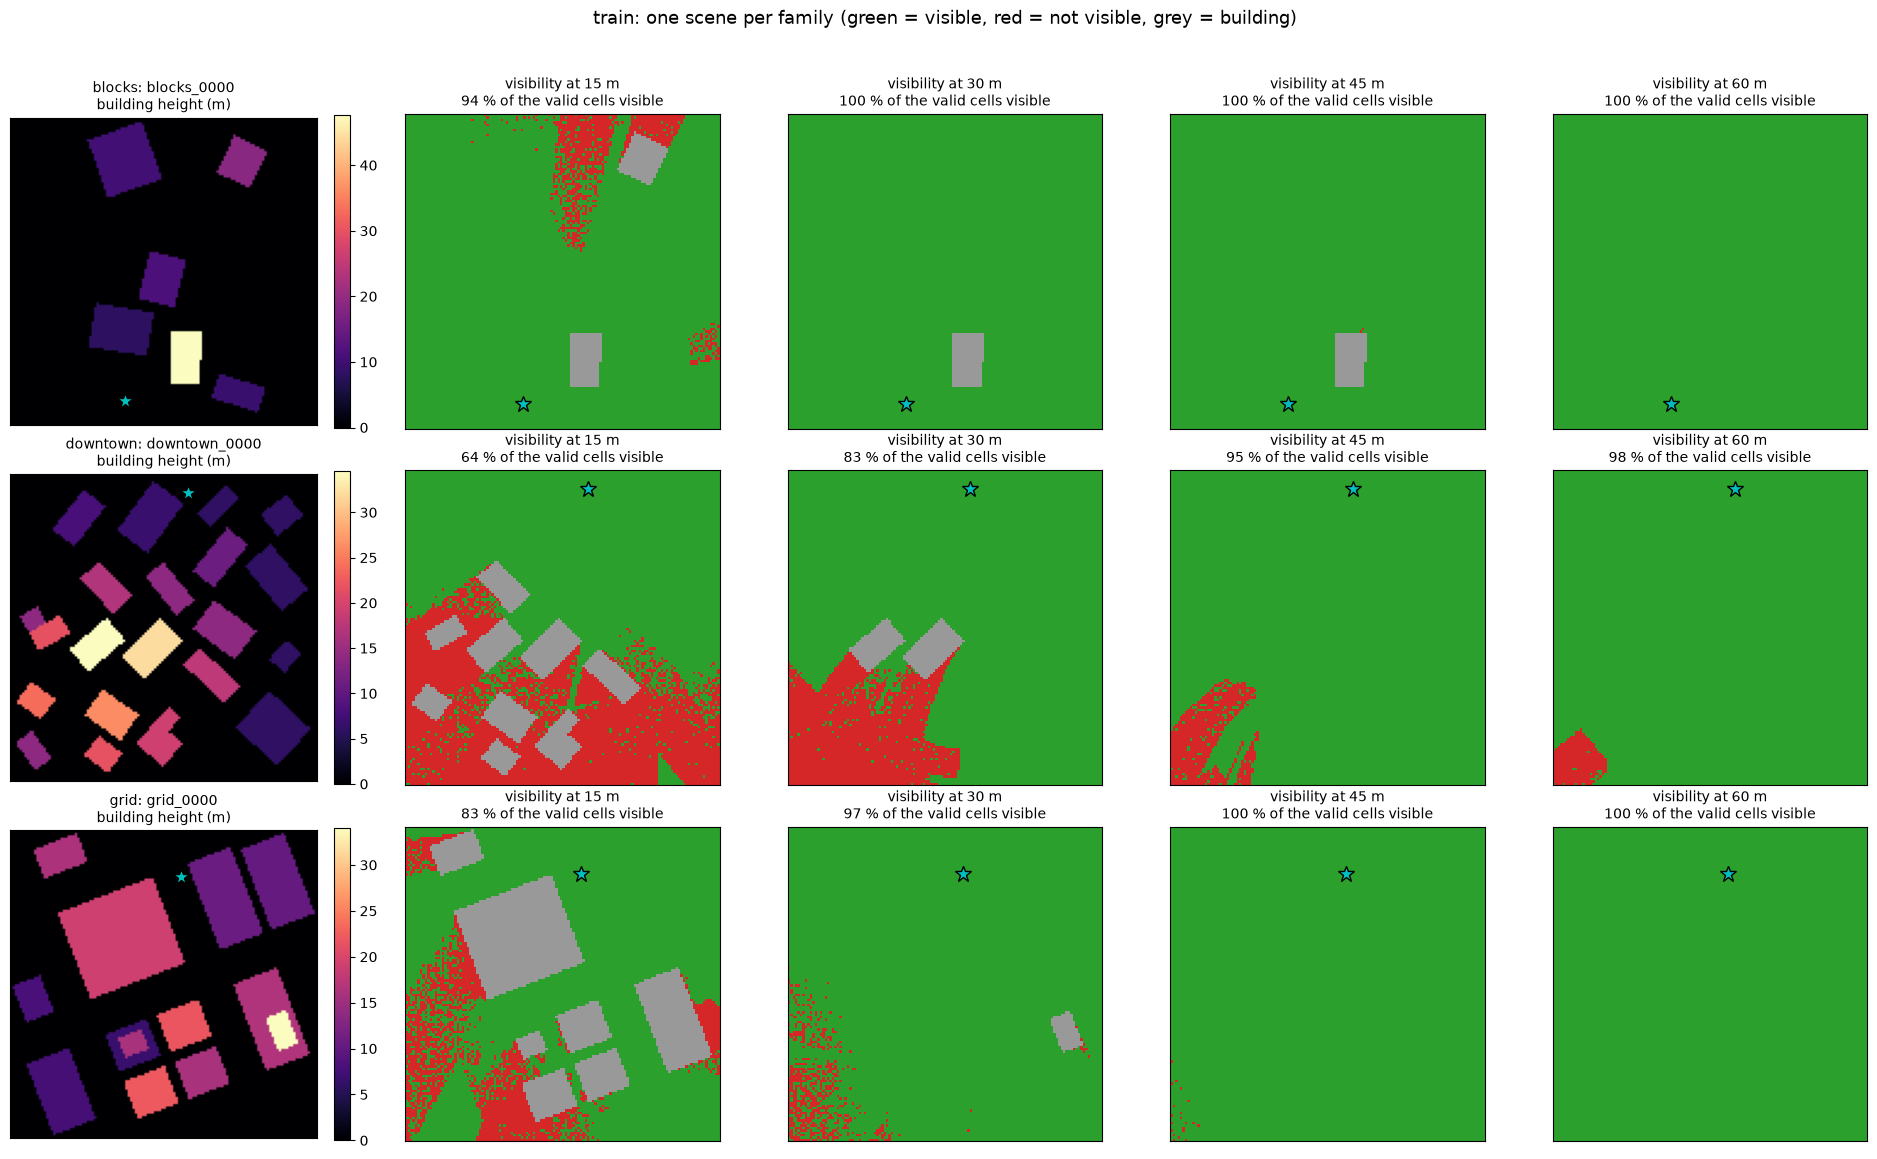

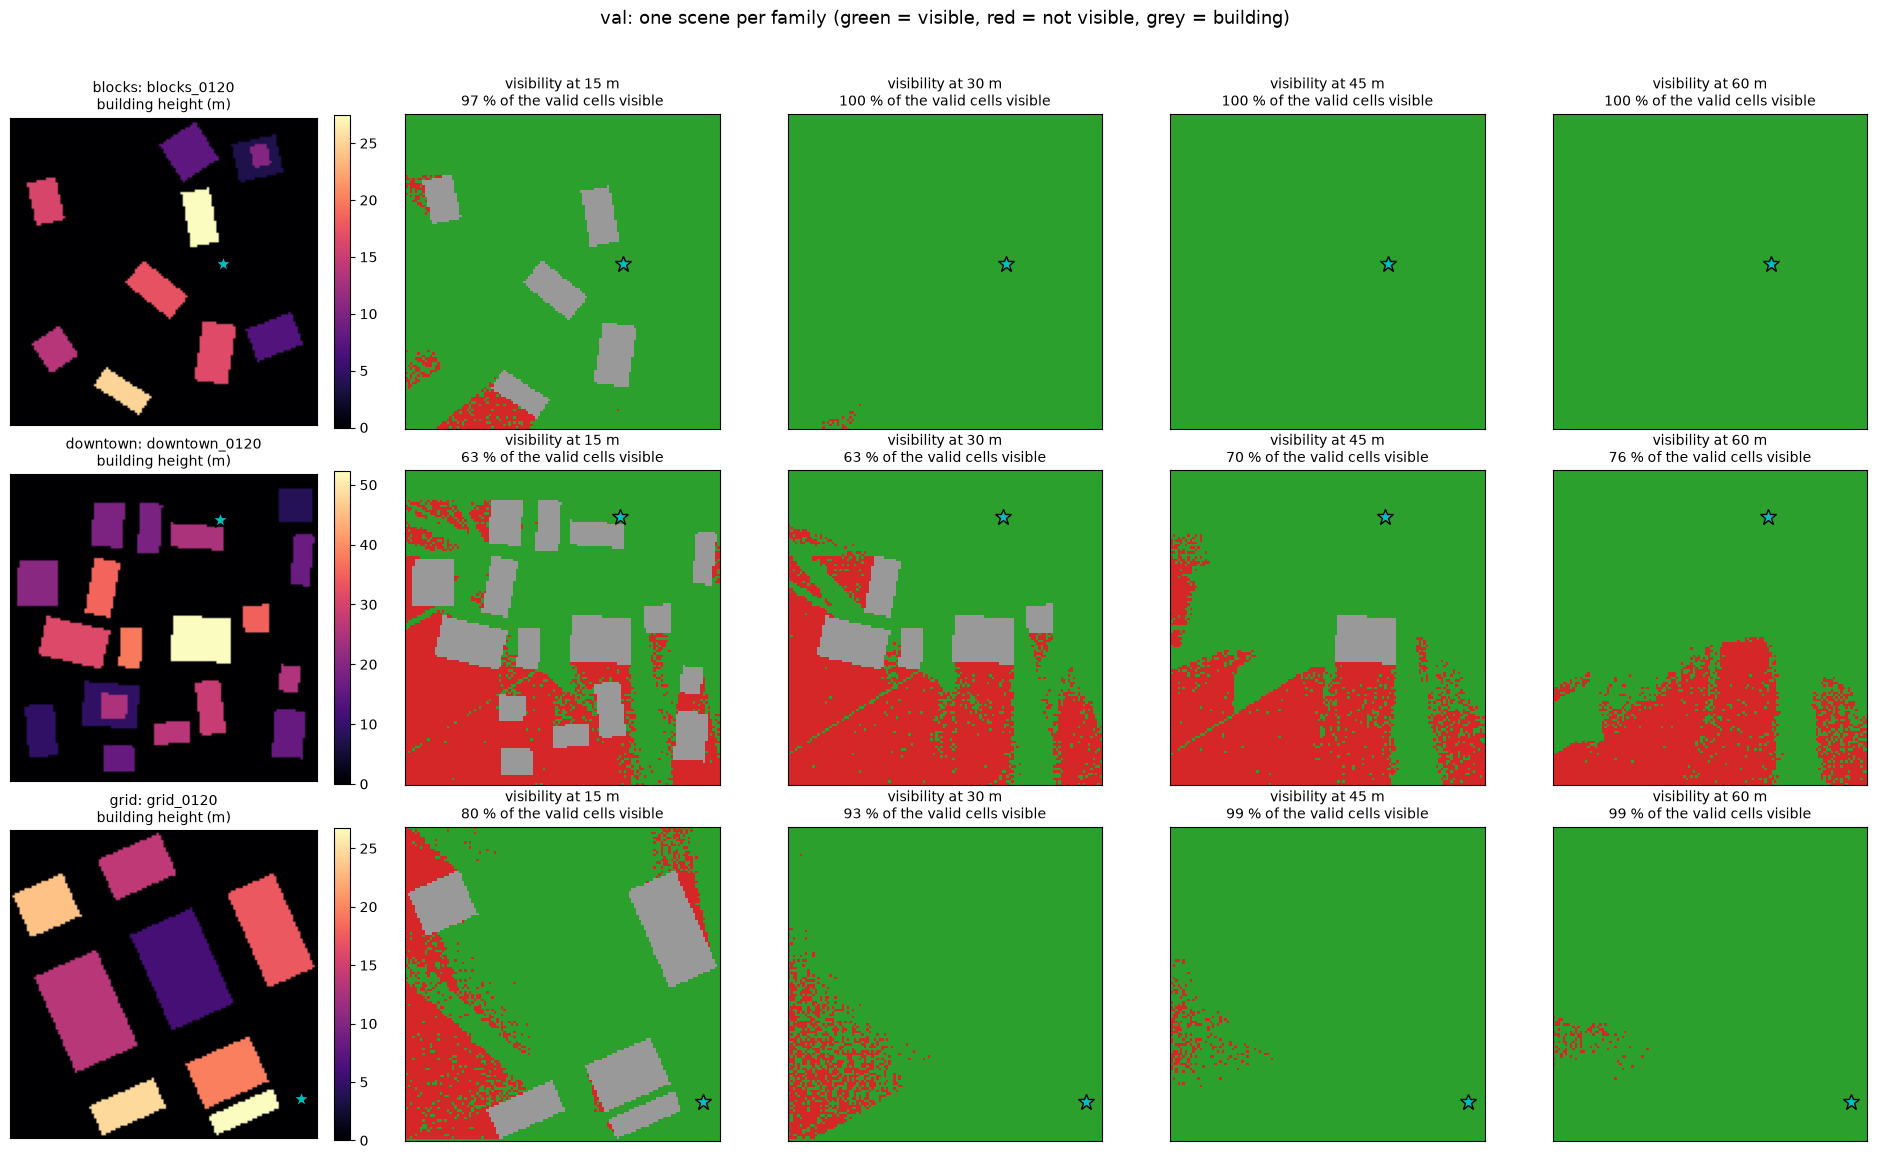

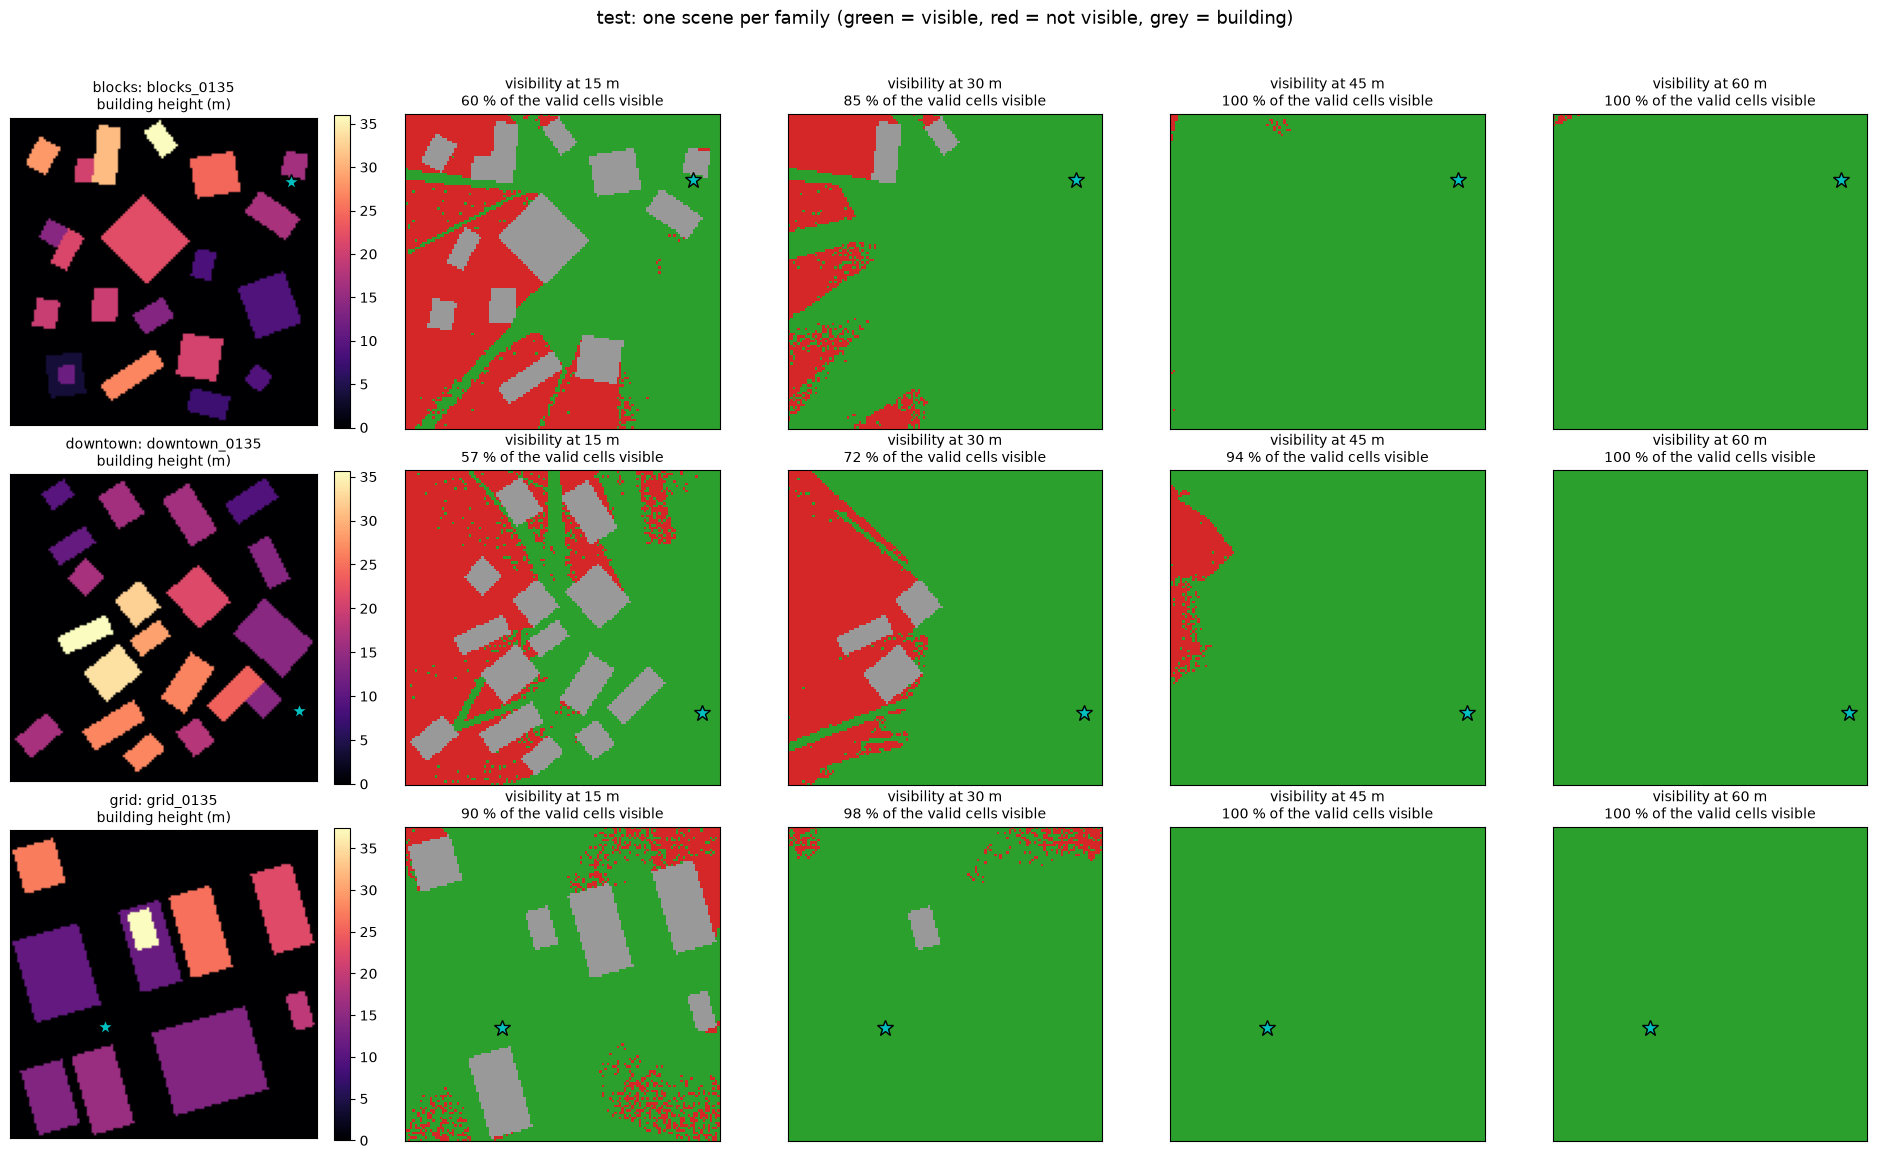

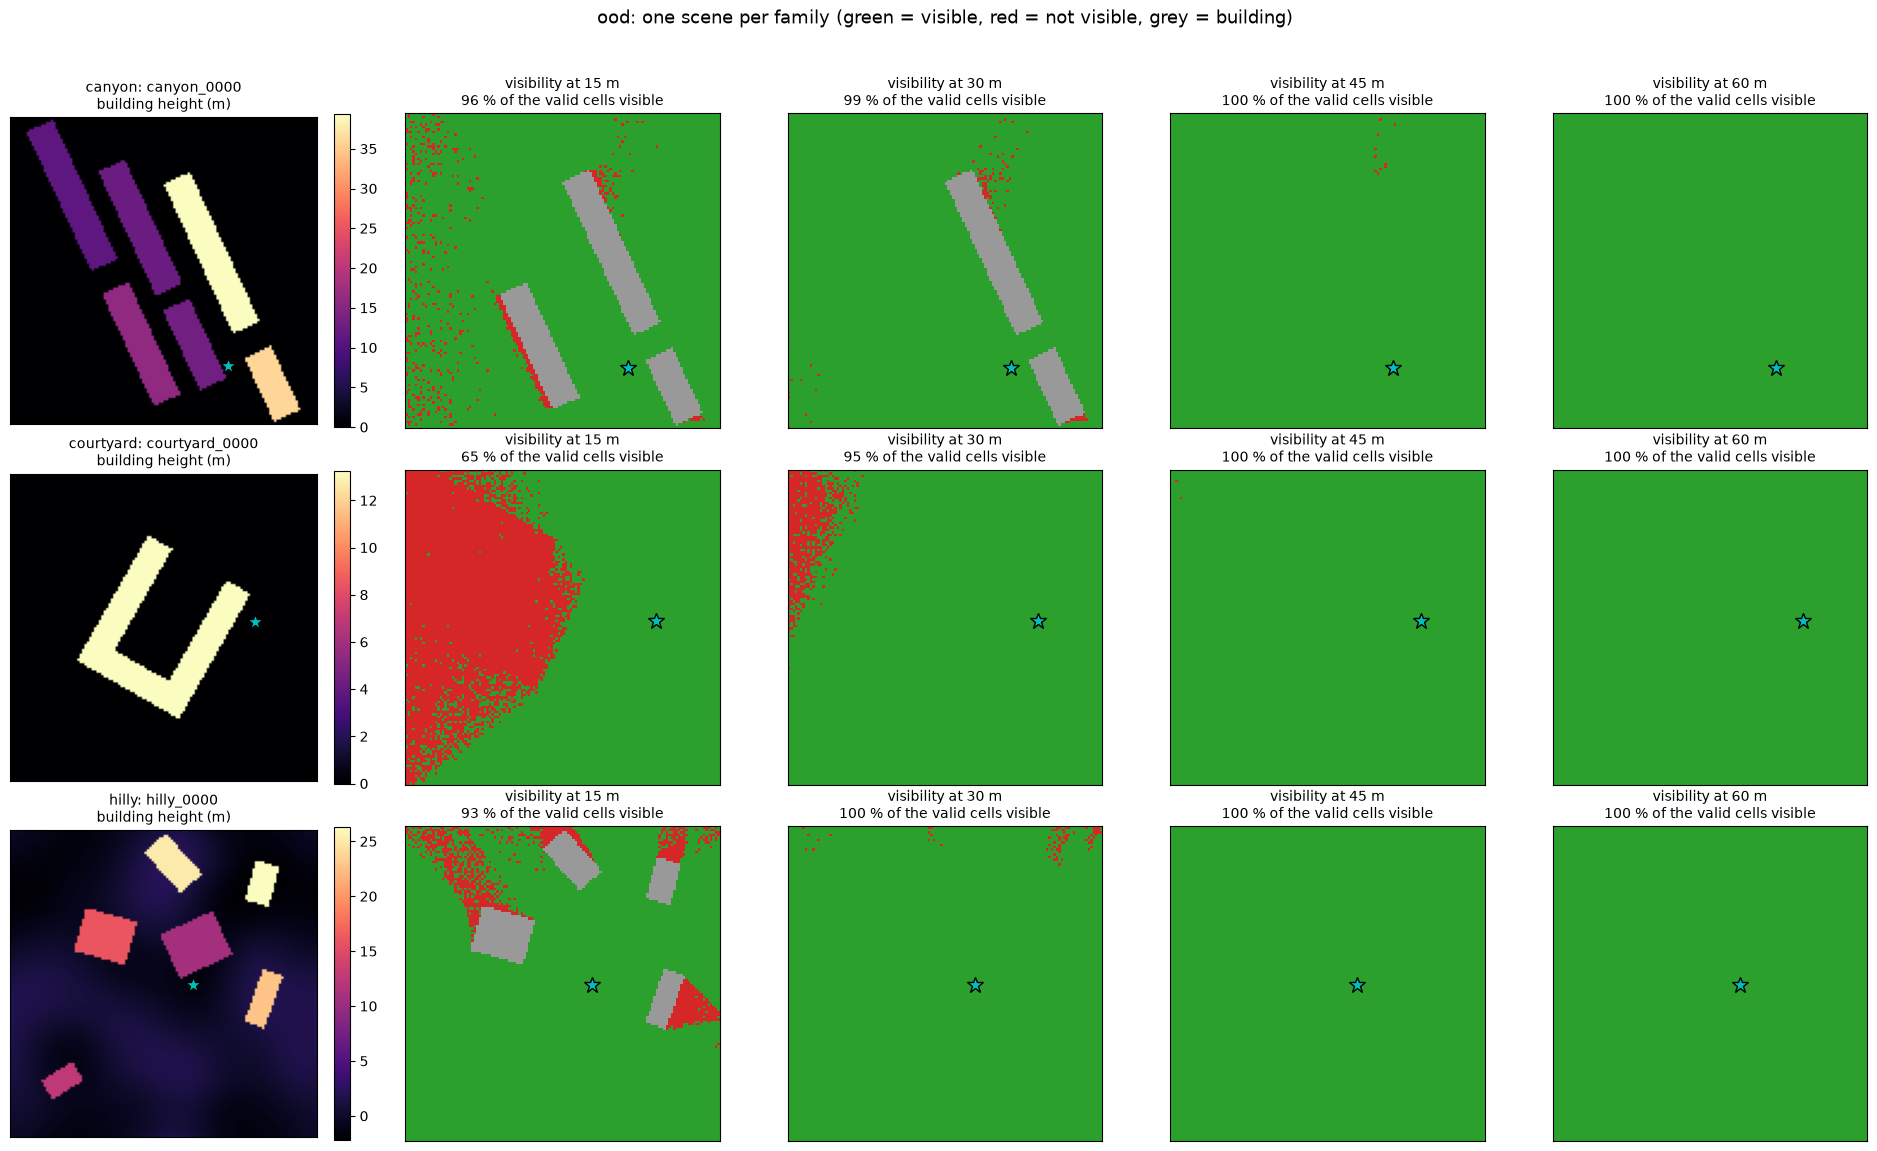

In [4]:
def family_examples(split):
    """One scene per family of a split: building heights and the visibility at every altitude of one station."""
    f = np.load(VIS_DIR / f"visibility_{split}.npz")
    names, sidx, alt, st = f["scene_names"], f["scene_idx"], f["altitude"], f["station_pos"]
    v, ok, h = f["visibility"], f["valid"], f["heights"]
    families = sorted({str(n).rsplit("_", 1)[0] for n in names})
    alts = np.unique(alt)
    fig, axes = plt.subplots(len(families), 1 + len(alts), figsize=(3.8 * (1 + len(alts)), 3.9 * len(families)),
                             squeeze=False)
    for row, fam in zip(axes, families):
        s = next(i for i, n in enumerate(names) if str(n).startswith(fam + "_"))
        ks = np.where(sidx == s)[0]
        ks = sorted((k for k in ks if np.allclose(st[k], st[ks[0]])), key=lambda k: alt[k])   # first station
        im = row[0].imshow(h[s], origin="lower", cmap="magma", extent=EXTENT)
        row[0].set_title(f"{fam}: {names[s]}\nbuilding height (m)", fontsize=10)
        plt.colorbar(im, ax=row[0], fraction=0.046)
        for ax, k in zip(row[1:], ks):
            ax.imshow(np.where(ok[k], v[k], 2), origin="lower", cmap=VIS_CMAP, vmin=-0.5, vmax=2.5, extent=EXTENT,
                      interpolation="nearest")
            ax.set_title(f"visibility at {alt[k]:.0f} m\n{100 * v[k][ok[k]].mean():.0f} % of the valid cells visible",
                         fontsize=10)
        for ax in row:
            ax.plot(st[ks[0], 0], st[ks[0], 1], "c*", ms=12, mec="k")
            ax.set_xticks([]), ax.set_yticks([])
    fig.suptitle(f"{split}: one scene per family (green = visible, red = not visible, grey = building)", fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


for split in ("train", "val", "test", "ood"):
    family_examples(split)

## Save every scene as an image (optional)
Writes one PNG per scene (the 12 maps of the scene) to `../dataset/visibility/images/<split>/`. Set `SAVE_ALL = True`
to run it; for `train` it writes 1,080 images.

In [5]:
SAVE_ALL = False

if SAVE_ALL:
    out_dir = VIS_DIR / "images" / SPLIT
    out_dir.mkdir(parents=True, exist_ok=True)
    show = plt.show
    for s in range(len(scene_names)):
        plt.show = lambda: (plt.savefig(out_dir / f"{s:04d}_{scene_names[s]}.png", dpi=80), plt.close())
        show_scene(s)
    plt.show = show
    print(f"{len(scene_names)} images written to {out_dir}")